# USA — Documented Incident Rates and National Factors

This notebook examines which economic and digital indicators are associated with publicly documented cyber incident rates in the United States (2014–2024), and whether the observed associations persist after sensitivity checks.

## Research questions and hypotheses

- **Q1:** Which of the nine economic and digital indicators are associated with documented incident rates?
- **Q2:** Are the observed associations sensitive to the exceptional incident peak in 2023?
- **Q3:** Do associations observed in annual levels persist when examining year-over-year changes?

For each of the nine indicators, we test the two-sided hypotheses $H_0: \rho_s=0$ versus $H_1: \rho_s\neq 0$. Internet adoption, establishment density, and GDP per capita are of particular substantive interest; the remaining factors are included in the same exploratory analysis.

## 1. Data and scope

Load the existing national factors dataset and verify the 2014–2024 complete-case sample, measurement units, and missing values. The 2025 digital indicators are unavailable and will not be imputed.

**Local dataset:** `data/processed/factors/usa_national_factors_2014_2025.csv`

**Original sources:** [World Bank WDI](https://data.worldbank.org/country/united-states) · [BEA](https://www.bea.gov/data/gdp/gdp-state) · [BLS QCEW](https://www.bls.gov/cew/) · [UMD Cyber Events Database](https://cissm.umd.edu/research-impact/publications/cyber-events-database)

**Scope note:** Incident rates use nationwide UMD events and national population, while establishment density covers the 50 states excluding Washington, D.C. The source data measure *publicly documented* events, not all cyber incidents.


Detailed indicator definitions, formulas, data sources, and methodological limitations are documented in [Factor definitions and methodology](../../docs/factors.md).


### 1.1 Load and validate the dataset

Confirm the year range, data completeness, and all ten indicators before analysis.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.stats.multitest import multipletests
from scipy.stats import pearsonr, spearmanr, shapiro

In [2]:
# Locate the project root
DATA_RELATIVE_PATH = Path(
    "data/processed/factors/usa_national_factors_2014_2025.csv"
)

PROJECT_ROOT = next(
    (
        path for path in [Path.cwd(), *Path.cwd().parents]
        if (path / DATA_RELATIVE_PATH).is_file()
    ),
    None,
)

assert PROJECT_ROOT is not None, "National factors dataset not found."

DATA_PATH = PROJECT_ROOT / DATA_RELATIVE_PATH
df = pd.read_csv(DATA_PATH)

print(f"Dataset: {DATA_PATH.relative_to(PROJECT_ROOT)}")
print(f"Shape: {df.shape}")
print(f"Years: {df['year'].min()}–{df['year'].max()}")


Dataset: data\processed\factors\usa_national_factors_2014_2025.csv
Shape: (12, 12)
Years: 2014–2025


In [3]:
factors = [
    "incident_rate",
    "gdp_per_capita",
    "gdp_growth",
    "industry_gdp_pct",
    "services_gdp_pct",
    "unemployment_rate",
    "labor_force_participation",
    "establishment_density",
    "internet_users_pct",
    "fixed_broadband_per_100",
]

assert df["country"].eq("USA").all()
assert df["year"].is_unique
assert set(df["year"]) == set(range(2014, 2026))
assert all(column in df.columns for column in factors)

availability = pd.DataFrame({
    "Indicator": factors,
    "Available years": df[factors].notna().sum().values,
    "Missing years": df[factors].isna().sum().values,
})

display(availability)


,Indicator,Available years,Missing years
0,incident_rate,12,0
1,gdp_per_capita,12,0
2,gdp_growth,12,0
3,industry_gdp_pct,12,0
4,services_gdp_pct,12,0
5,unemployment_rate,12,0
6,labor_force_participation,12,0
7,establishment_density,12,0
8,internet_users_pct,11,1
9,fixed_broadband_per_100,11,1


### 1.2 Prepare the analysis period

The correlation analysis uses 2014–2024, the period for which all ten indicators are available. The original dataset retains 2025 for analyses that do not require the two missing digital indicators.


In [4]:
# Select the common analysis period
df_analysis = df.loc[
    df["year"].between(2014, 2024),
    ["year", *factors]
].copy()

assert len(df_analysis) == 11
assert not df_analysis[factors].isna().any().any()

print(f"Analysis period: {df_analysis['year'].min()}–{df_analysis['year'].max()}")
print(f"Observations: {len(df_analysis)}")
print(f"Indicators: {len(factors)}")
print(f"Missing values: {df_analysis[factors].isna().sum().sum()}")


Analysis period: 2014–2024
Observations: 11
Indicators: 10
Missing values: 0


## 2. Annual trends

This section compares documented incident rates with selected economic and digital indicators over time.

### 2.1 Compare annual trends

The incident rate is shown in its original units. The other indicators are expressed as percentage changes relative to 2014, allowing trends measured in different units to be compared without mixing scales.

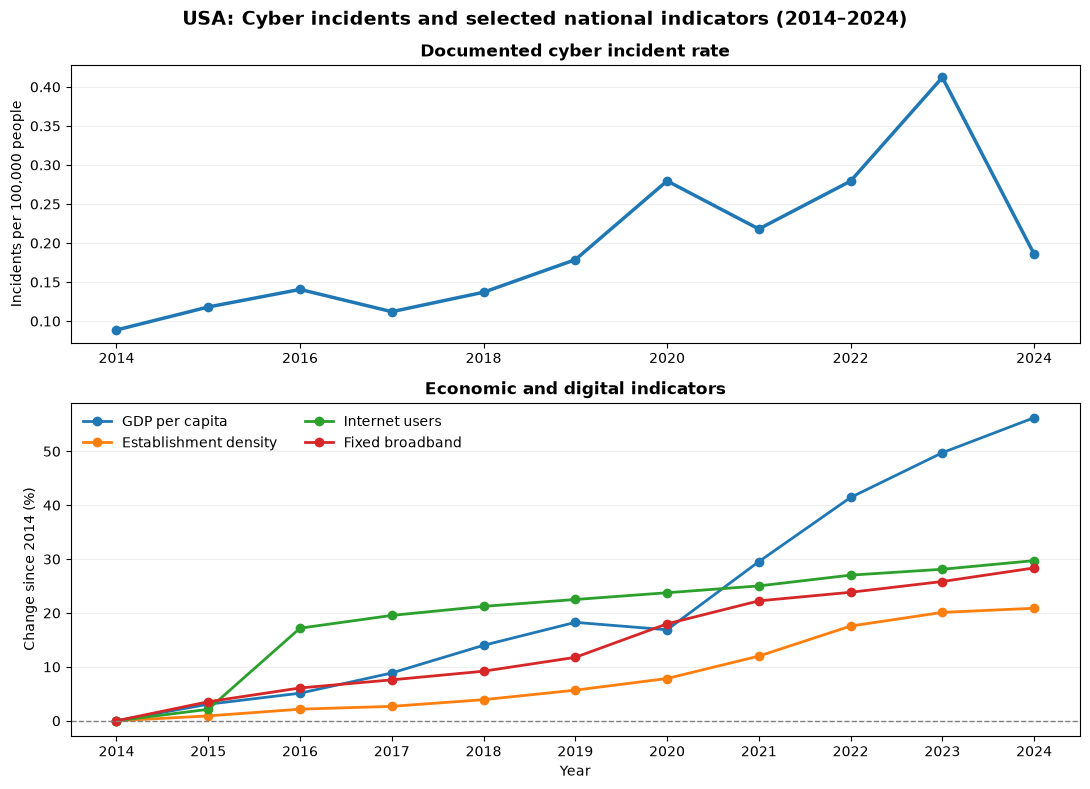

In [5]:

# Plot incident rates separately from economic and digital trends
trend_columns = [
    "gdp_per_capita",
    "establishment_density",
    "internet_users_pct",
    "fixed_broadband_per_100",
]

trend_labels = {
    "gdp_per_capita": "GDP per capita",
    "establishment_density": "Establishment density",
    "internet_users_pct": "Internet users",
    "fixed_broadband_per_100": "Fixed broadband",
}

trend = df_analysis.set_index("year")[trend_columns]
relative_change = (trend.div(trend.iloc[0]) - 1) * 100

fig, axes = plt.subplots(
    2, 1, figsize=(11, 8),
    sharex=False,
    gridspec_kw={"height_ratios": [1, 1.2]},
)

axes[0].plot(
    df_analysis["year"],
    df_analysis["incident_rate"],
    color="tab:blue",
    marker="o",
    linewidth=2.5,
)

axes[0].set_title("Documented cyber incident rate", fontweight="bold")
axes[0].set_ylabel("Incidents per 100,000 people")
axes[0].grid(axis="y", alpha=0.2)

for column in trend_columns:
    axes[1].plot(
        relative_change.index,
        relative_change[column],
        marker="o",
        linewidth=2,
        label=trend_labels[column],
    )

axes[1].axhline(0, color="gray", linewidth=1, linestyle="--")
axes[1].set_title("Economic and digital indicators", fontweight="bold")
axes[1].set_ylabel("Change since 2014 (%)")
axes[1].set_xlabel("Year")
axes[1].set_xticks(df_analysis["year"])
axes[1].grid(axis="y", alpha=0.2)
axes[1].legend(frameon=False, ncol=2)

fig.suptitle(
    "USA: Cyber incidents and selected national indicators (2014–2024)",
    fontsize=14,
    fontweight="bold",
)

fig.tight_layout()
plt.show()



### 2.2 Key findings

- Documented incident rates fluctuated considerably, peaking in 2023 before declining in 2024.
- GDP per capita, establishment density, internet usage, and fixed broadband generally increased throughout 2014–2024.
- Economic and digital indicators followed relatively steady upward trends, while documented incident rates showed substantial annual fluctuations.


## 3. Correlations and hypothesis tests

We first report the complete Pearson correlation matrix (10 × 10) for descriptive cross-country comparison, then use Spearman's rank correlation consistently to test associations between the incident rate and all nine factors. Significance results are exploratory because there are only 11 annual observations and common time trends may affect conventional p-values.

### 3.1 Pearson correlation matrix


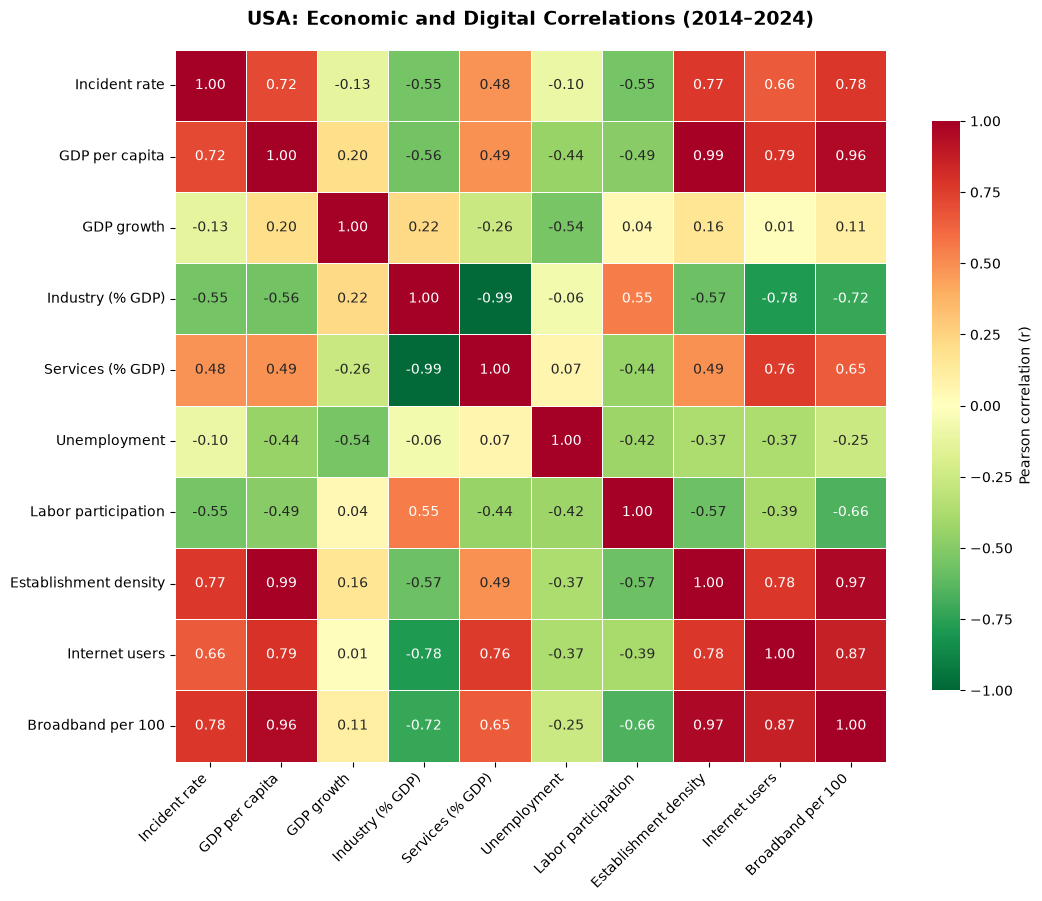

In [6]:
# Pearson correlation matrix for all ten indicators
pearson_corr = df_analysis[factors].corr(method="pearson")

labels = [
    "Incident rate",
    "GDP per capita",
    "GDP growth",
    "Industry (% GDP)",
    "Services (% GDP)",
    "Unemployment",
    "Labor participation",
    "Establishment density",
    "Internet users",
    "Broadband per 100",
]

fig, ax = plt.subplots(figsize=(11, 9))

sns.heatmap(
    pearson_corr,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn_r",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    linecolor="white",
    xticklabels=labels,
    yticklabels=labels,
    annot_kws={"size": 10},
    cbar_kws={
        "label": "Pearson correlation (r)",
        "shrink": 0.8,
    },
    ax=ax,
)

ax.set_title(
    "USA: Economic and Digital Correlations (2014–2024)",
    fontsize=14,
    fontweight="bold",
    pad=18,
)

ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=45,
    ha="right",
    fontsize=10,
)

ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0,
    fontsize=10,
)

fig.tight_layout()

# Save the correlation matrix
figure_name = "01_pearson_correlation_matrix_2014_2024.png"

output_dirs = [
    PROJECT_ROOT / "figures/factors/static",
    PROJECT_ROOT / "ugotovitve/dejavnike",
]

for output_dir in output_dirs:
    output_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(
        output_dir / figure_name,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

plt.show()

### 3.2 Key findings — Pearson matrix

- The strongest positive Pearson correlations with documented incident rates were fixed broadband ($r=0.78$), establishment density ($r=0.77$), GDP per capita ($r=0.72$), and internet usage ($r=0.66$).
- GDP growth ($r=-0.13$) and unemployment ($r=-0.10$) showed weak linear associations.
- GDP per capita, establishment density, and fixed broadband were strongly correlated with one another ($r=0.96$–$0.99$).
- Industry and services shares were strongly negatively correlated ($r=-0.99$), partly reflecting their shared GDP denominator.

**Note:** This matrix describes linear relationships only. Statistical tests of the nine incident-rate associations use Spearman's correlation in Section 3.5.

### 3.3 Normality assessment

The Shapiro–Wilk test provides a descriptive diagnostic of the ten distributions ($n=11$, $\alpha=0.05$):

- $H_0$: The sample comes from a normal distribution.
- $H_1$: The sample does not come from a normal distribution.

With only 11 observations, failing to reject normality does not establish normality. **The Shapiro–Wilk result is not used as an automatic rule for selecting the correlation method.**

In [7]:
# Test normality of all ten indicators
normality_results = []

for factor in factors:
    statistic, p_value = shapiro(df_analysis[factor])

    normality_results.append({
        "Indicator": factor,
        "Shapiro W": statistic,
        "p-value": p_value,
        "Reject normality (p < 0.05)": p_value < 0.05,
    })

normality_df = pd.DataFrame(normality_results)

display(normality_df.round({
    "Shapiro W": 4,
    "p-value": 4,
}))

,Indicator,Shapiro W,p-value,Reject normality (p < 0.05)
0,incident_rate,0.8939,0.1557,False
1,gdp_per_capita,0.9033,0.2025,False
2,gdp_growth,0.7558,0.0025,True
3,industry_gdp_pct,0.9389,0.5073,False
4,services_gdp_pct,0.9325,0.4369,False
5,unemployment_rate,0.8381,0.0298,True
6,labor_force_participation,0.9515,0.6633,False
7,establishment_density,0.8702,0.0779,False
8,internet_users_pct,0.8229,0.0188,True
9,fixed_broadband_per_100,0.9339,0.4520,False


### 3.4 Distribution histograms

Histograms supplement the Shapiro–Wilk diagnostics. With only 11 values per indicator, their shapes should not be overinterpreted.

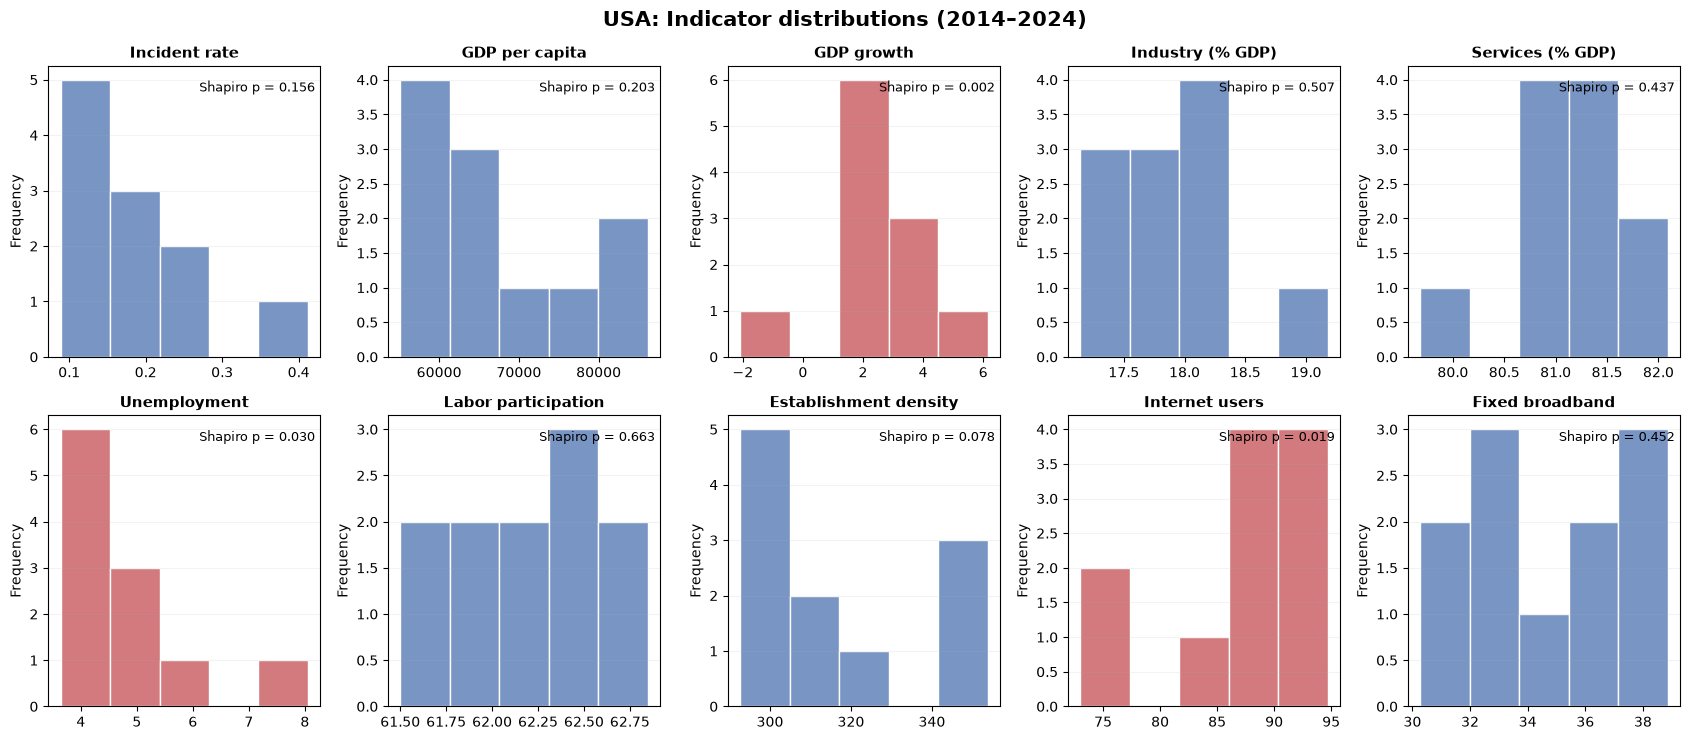

In [8]:
# Visualize the distributions of all ten indicators
indicator_labels = {
    "incident_rate": "Incident rate",
    "gdp_per_capita": "GDP per capita",
    "gdp_growth": "GDP growth",
    "industry_gdp_pct": "Industry (% GDP)",
    "services_gdp_pct": "Services (% GDP)",
    "unemployment_rate": "Unemployment",
    "labor_force_participation": "Labor participation",
    "establishment_density": "Establishment density",
    "internet_users_pct": "Internet users",
    "fixed_broadband_per_100": "Fixed broadband",
}

fig, axes = plt.subplots(2, 5, figsize=(17, 7.5))
axes = axes.flatten()

for ax, factor in zip(axes, factors):
    values = df_analysis[factor].dropna()

    p_value = normality_df.loc[
        normality_df["Indicator"] == factor, "p-value"
    ].iloc[0]

    color = "#C44E52" if p_value < 0.05 else "#4C72B0"

    sns.histplot(
        values,
        bins=5,
        color=color,
        edgecolor="white",
        ax=ax,
    )

    ax.set_title(
        indicator_labels[factor],
        fontsize=11,
        fontweight="bold",
    )
    ax.text(
        0.98, 0.95,
        f"Shapiro p = {p_value:.3f}",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=9,
    )

    ax.set_xlabel("")
    ax.set_ylabel("Frequency")
    ax.grid(axis="y", alpha=0.15)

fig.suptitle(
    "USA: Indicator distributions (2014–2024)",
    fontsize=15,
    fontweight="bold",
)

fig.tight_layout()
plt.show()



### 3.5 Correlation tests

Due to the small sample size ($n=11$), the Shapiro–Wilk test has limited statistical power, making normality difficult to assess reliably. Therefore, **Spearman's rank correlation is used consistently for all nine factors**, rather than selecting Pearson or Spearman based solely on normality tests.

Spearman's coefficient ($\rho$) measures the strength and direction of monotonic associations without requiring normally distributed variables.

For each factor, we test:

- $H_0$: There is no monotonic association with the documented incident rate.
- $H_1$: There is a monotonic association with the documented incident rate.

All tests are two-sided ($\alpha=0.05$), with Benjamini–Hochberg correction for nine comparisons. P-values are interpreted cautiously because the observations form a short annual time series.


In [9]:

# Spearman correlations for all nine factors
results = []

for factor in factors:
    if factor == "incident_rate":
        continue

    coefficient, p_value = spearmanr(
        df_analysis[factor],
        df_analysis["incident_rate"],
    )

    results.append({
        "Factor": factor,
        "Method": "Spearman",
        "N": len(df_analysis),
        "Correlation": coefficient,
        "p-value": p_value,
    })

correlation_tests = pd.DataFrame(results)

correlation_tests["BH-adjusted p"] = multipletests(
    correlation_tests["p-value"],
    method="fdr_bh",
)[1]

correlation_tests["Significant (BH)"] = (
    correlation_tests["BH-adjusted p"] < 0.05
)

correlation_tests = correlation_tests.sort_values(
    "Correlation",
    key=lambda values: values.abs(),
    ascending=False,
).reset_index(drop=True)

display(correlation_tests.round({
    "Correlation": 3,
    "p-value": 4,
    "BH-adjusted p": 4,
}))


,Factor,Method,N,Correlation,p-value,BH-adjusted p,Significant (BH)
0,internet_users_pct,Spearman,11,0.836,0.0013,0.0040,True
1,establishment_density,Spearman,11,0.836,0.0013,0.0040,True
2,fixed_broadband_per_100,Spearman,11,0.836,0.0013,0.0040,True
3,gdp_per_capita,Spearman,11,0.800,0.0031,0.0070,True
4,industry_gdp_pct,Spearman,11,-0.782,0.0045,0.0081,True
5,labor_force_participation,Spearman,11,-0.664,0.0260,0.0390,True
6,services_gdp_pct,Spearman,11,0.627,0.0388,0.0499,True
7,unemployment_rate,Spearman,11,-0.318,0.3403,0.3828,False
8,gdp_growth,Spearman,11,0.064,0.8525,0.8525,False


### 3.6 Key findings — Spearman tests

Seven of the nine factors showed associations with incident-rate levels that were statistically significant under the conventional Spearman tests after Benjamini–Hochberg adjustment ($n=11$, $\alpha=0.05$):

- **Positive:** Internet usage ($\rho=0.836$, adjusted $p=0.0040$), establishment density ($\rho=0.836$, adjusted $p=0.0040$), fixed broadband ($\rho=0.836$, adjusted $p=0.0040$), GDP per capita ($\rho=0.800$, adjusted $p=0.0070$), and services share ($\rho=0.627$, adjusted $p=0.0499$).
- **Negative:** Industry share ($\rho=-0.782$, adjusted $p=0.0081$) and labor force participation ($\rho=-0.664$, adjusted $p=0.0390$).
- **Not significant:** Unemployment and GDP growth.

**Interpretation:** These are exploratory level associations, not robust evidence of causal relationships. The tests treat yearly observations as independent, an assumption that may be violated by shared trends and serial dependence. Sections 3.8–3.10 examine sensitivity to those concerns.

### 3.7 Statistical significance of factors

The figure summarizes Spearman correlations between all nine factors and documented incident-rate levels. Green bars indicate associations with BH-adjusted $p<0.05$ under the conventional test; gray bars indicate the remaining associations. These labels are exploratory because annual observations may not be independent.

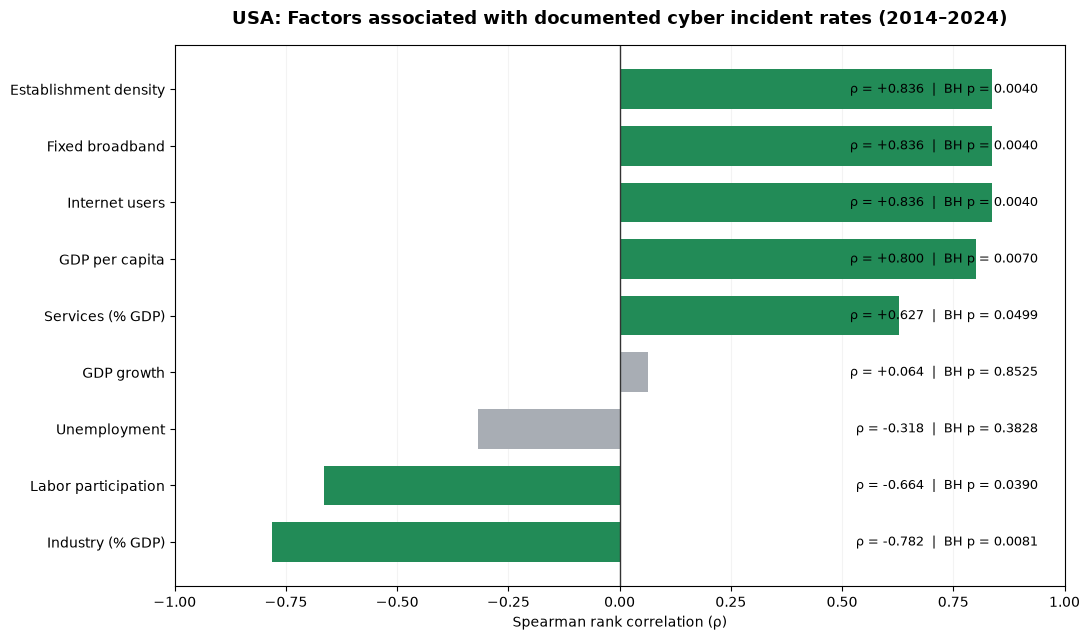

In [11]:
# Visualize correlation strength and BH-adjusted significance
plot_df = correlation_tests.copy().sort_values("Correlation")

factor_labels = {
    "gdp_per_capita": "GDP per capita",
    "gdp_growth": "GDP growth",
    "industry_gdp_pct": "Industry (% GDP)",
    "services_gdp_pct": "Services (% GDP)",
    "unemployment_rate": "Unemployment",
    "labor_force_participation": "Labor participation",
    "establishment_density": "Establishment density",
    "internet_users_pct": "Internet users",
    "fixed_broadband_per_100": "Fixed broadband",
}

fig, ax = plt.subplots(figsize=(11, 6.5))

colors = [
    "#228B57" if significant else "#A8ADB4"
    for significant in plot_df["Significant (BH)"]
]

bars = ax.barh(
    plot_df["Factor"].map(factor_labels),
    plot_df["Correlation"],
    color=colors,
    height=0.7,
)

for bar, (_, row) in zip(bars, plot_df.iterrows()):
    coefficient = row["Correlation"]
    adjusted_p = row["BH-adjusted p"]

    ax.text(
        0.97,
        bar.get_y() + bar.get_height() / 2,
        f"ρ = {coefficient:+.3f}  |  BH p = {adjusted_p:.4f}",
        va="center",
        ha="right",
        fontsize=9,
        transform=ax.get_yaxis_transform(),
    )

ax.axvline(0, color="#333333", linewidth=1)
ax.set_xlim(-1, 1)
ax.set_xlabel("Spearman rank correlation (ρ)")
ax.set_title(
    "USA: Factors associated with documented cyber incident rates (2014–2024)",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)

fig.tight_layout()

# Save figure
figure_name = "01_incident_rate_factor_significance_2014_2024.png"

for output_dir in [
    PROJECT_ROOT / "figures/factors/static",
    PROJECT_ROOT / "ugotovitve/dejavnike",
]:
    output_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(
        output_dir / figure_name,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

plt.show()

### 3.8 Sensitivity to the 2023 incident peak

The documented incident rate peaked in 2023. We recalculate all nine Spearman correlations after excluding this year to assess how sensitive the results are to the exceptional peak. The method remains the same in both samples.

In [12]:
# Recalculate correlations after excluding 2023
df_without_2023 = df_analysis.loc[
    df_analysis["year"] != 2023
].copy()

sensitivity_results = []

for _, row in correlation_tests.iterrows():
    factor = row["Factor"]
    coefficient, p_value = spearmanr(
        df_without_2023[factor],
        df_without_2023["incident_rate"],
    )

    sensitivity_results.append({
        "Factor": factor,
        "Full sample (n=11)": row["Correlation"],
        "Without 2023 (n=10)": coefficient,
        "Change in rho": coefficient - row["Correlation"],
        "p-value (n=10)": p_value,
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

display(
    sensitivity_df.round({
        "Full sample (n=11)": 3,
        "Without 2023 (n=10)": 3,
        "Change in rho": 3,
        "p-value (n=10)": 4,
    })
)

,Factor,Full sample (n=11),Without 2023 (n=10),Change in rho,p-value (n=10)
0,internet_users_pct,0.836,0.830,-0.006,0.0029
1,establishment_density,0.836,0.830,-0.006,0.0029
2,fixed_broadband_per_100,0.836,0.830,-0.006,0.0029
3,gdp_per_capita,0.800,0.782,-0.018,0.0075
4,industry_gdp_pct,-0.782,-0.806,-0.024,0.0049
5,labor_force_participation,-0.664,-0.673,-0.009,0.0330
6,services_gdp_pct,0.627,0.733,0.106,0.0158
7,unemployment_rate,-0.318,-0.091,0.227,0.8028
8,gdp_growth,0.064,-0.030,-0.094,0.9338


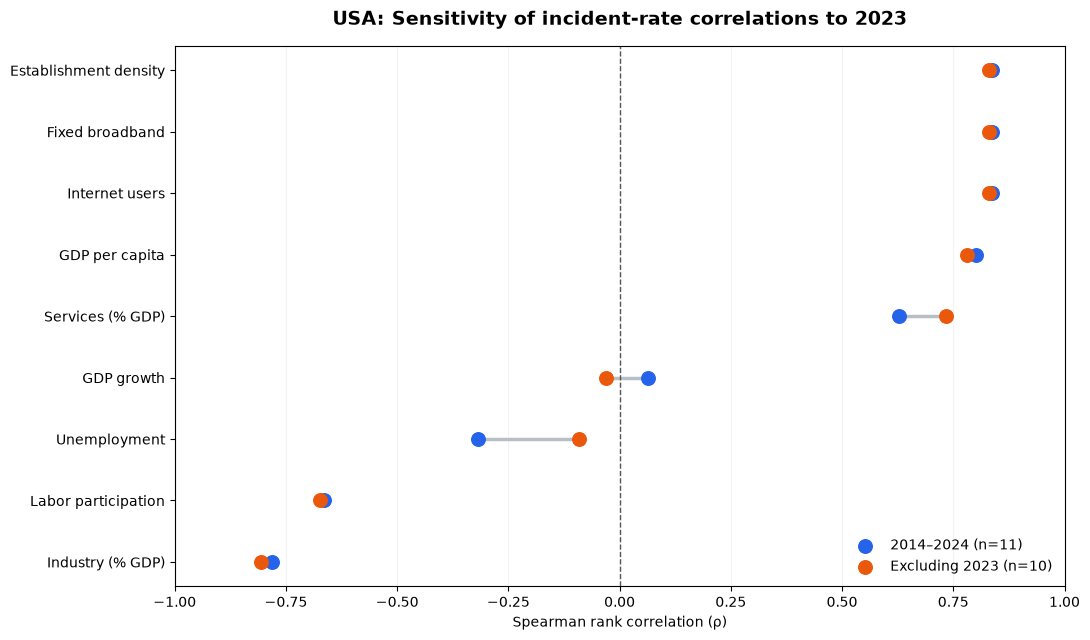

In [14]:
# Compare correlations with and without 2023
plot_df = sensitivity_df.sort_values(
    "Full sample (n=11)"
).reset_index(drop=True)

factor_labels = {
    "internet_users_pct": "Internet users",
    "fixed_broadband_per_100": "Fixed broadband",
    "establishment_density": "Establishment density",
    "gdp_per_capita": "GDP per capita",
    "industry_gdp_pct": "Industry (% GDP)",
    "labor_force_participation": "Labor participation",
    "services_gdp_pct": "Services (% GDP)",
    "unemployment_rate": "Unemployment",
    "gdp_growth": "GDP growth",
}

y = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(11, 6.5))

# Connect the two estimates
for i, row in plot_df.iterrows():
    ax.plot(
        [row["Full sample (n=11)"], row["Without 2023 (n=10)"]],
        [i, i],
        color="#B8BEC6",
        linewidth=2.5,
        zorder=1,
    )

ax.scatter(
    plot_df["Full sample (n=11)"],
    y,
    color="#2563EB",
    s=95,
    label="2014–2024 (n=11)",
    zorder=3,
)

ax.scatter(
    plot_df["Without 2023 (n=10)"],
    y,
    color="#EA580C",
    s=95,
    label="Excluding 2023 (n=10)",
    zorder=4,
)

ax.axvline(0, color="#555555", linestyle="--", linewidth=1)

ax.set_yticks(y)
ax.set_yticklabels(plot_df["Factor"].map(factor_labels))
ax.set_xlim(-1, 1)
ax.set_xlabel("Spearman rank correlation (ρ)")

ax.set_title(
    "USA: Sensitivity of incident-rate correlations to 2023",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)
ax.legend(loc="lower right", frameon=False)

fig.tight_layout()

# Save figure
figure_name = "01_correlation_sensitivity_2023.png"

for output_dir in [
    PROJECT_ROOT / "figures/factors/static",
    PROJECT_ROOT / "ugotovitve/dejavnike",
]:
    output_dir.mkdir(parents=True, exist_ok=True)

    fig.savefig(
        output_dir / figure_name,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

plt.show()

**Key findings — Excluding 2023**

- Spearman correlations for internet usage, fixed broadband, and establishment density each changed only slightly ($\rho=0.836 \rightarrow 0.830$).
- GDP per capita remained positively associated ($\rho=0.800 \rightarrow 0.782$); industry share remained negatively associated ($\rho=-0.782 \rightarrow -0.806$).
- Services share increased from $\rho=0.627$ to $0.733$, while unemployment moved closer to zero ($\rho=-0.318 \rightarrow -0.091$).

**Conclusion:** The strongest level correlations are not driven solely by the 2023 peak. This check does not rule out correlations arising from shared long-term trends.


### 3.9 Correlations of annual changes

<div align="center">

***Do years with larger increases in economic and digital indicators also experience larger increases in documented cyber incident rates?***

</div>

The previous analysis compared annual indicator levels. However, two indicators may be strongly correlated simply because both increase over time.

To examine whether their year-to-year movements are associated, we calculate annual changes:

$$
\Delta X_t = X_t - X_{t-1}
$$

We then correlate changes in each economic or digital indicator with changes in the documented incident rate (2015–2024).

This approach reduces the influence of shared long-term trends, but does not eliminate all temporal dependencies. Only ten annual changes are available, so the results remain exploratory.


In [16]:
# Calculate year-over-year changes
df_changes = (
    df_analysis
    .sort_values("year")
    .set_index("year")[factors]
    .diff()
    .dropna()
)

assert len(df_changes) == 10

print(f"Period: {df_changes.index.min()}–{df_changes.index.max()}")
print(f"Annual changes: {len(df_changes)}")
print(f"Missing values: {df_changes.isna().sum().sum()}")


Period: 2015–2024
Annual changes: 10
Missing values: 0


#### 3.9.1 Normality of annual changes

The Shapiro–Wilk test is applied to annual changes in all ten indicators ($n=10$, $\alpha=0.05$) as a descriptive diagnostic. Because the sample is small, it cannot establish normality and is **not used to choose the correlation method**. Spearman's rank correlation is used consistently for annual levels and changes.

In [17]:
# Assess normality of annual changes
change_normality_results = []

for factor in factors:
    statistic, p_value = shapiro(df_changes[factor])

    change_normality_results.append({
        "Indicator": factor,
        "Shapiro W": statistic,
        "p-value": p_value,
        "Reject normality": p_value < 0.05,
    })

change_normality_df = pd.DataFrame(change_normality_results)

display(change_normality_df.round({
    "Shapiro W": 4,
    "p-value": 4,
}))


,Indicator,Shapiro W,p-value,Reject normality
0,incident_rate,0.8773,0.1214,False
1,gdp_per_capita,0.9575,0.7565,False
2,gdp_growth,0.8181,0.0240,True
3,industry_gdp_pct,0.8799,0.1303,False
4,services_gdp_pct,0.8754,0.1155,False
5,unemployment_rate,0.8097,0.0190,True
6,labor_force_participation,0.6983,0.0008,True
7,establishment_density,0.8505,0.0589,False
8,internet_users_pct,0.4572,0.0000,True
9,fixed_broadband_per_100,0.8385,0.0424,True


In [18]:

# Spearman correlations of annual changes
change_results = []

for factor in factors:
    if factor == "incident_rate":
        continue

    coefficient, p_value = spearmanr(
        df_changes[factor],
        df_changes["incident_rate"],
    )

    change_results.append({
        "Factor": factor,
        "Method": "Spearman",
        "N": len(df_changes),
        "Correlation": coefficient,
        "p-value": p_value,
    })

change_tests = pd.DataFrame(change_results)

change_tests["BH-adjusted p"] = multipletests(
    change_tests["p-value"],
    method="fdr_bh",
)[1]

change_tests["Significant (BH)"] = (
    change_tests["BH-adjusted p"] < 0.05
)

change_tests = change_tests.sort_values(
    "Correlation",
    key=lambda values: values.abs(),
    ascending=False,
).reset_index(drop=True)

display(change_tests.round({
    "Correlation": 3,
    "p-value": 4,
    "BH-adjusted p": 4,
}))


,Factor,Method,N,Correlation,p-value,BH-adjusted p,Significant (BH)
0,gdp_growth,Spearman,10,-0.527,0.1173,0.5279,False
1,establishment_density,Spearman,10,0.527,0.1173,0.5279,False
2,internet_users_pct,Spearman,10,-0.418,0.2291,0.6873,False
3,labor_force_participation,Spearman,10,0.321,0.3655,0.7885,False
4,unemployment_rate,Spearman,10,0.273,0.4458,0.7885,False
5,industry_gdp_pct,Spearman,10,-0.176,0.6272,0.7885,False
6,gdp_per_capita,Spearman,10,-0.139,0.7009,0.7885,False
7,services_gdp_pct,Spearman,10,0.139,0.7009,0.7885,False
8,fixed_broadband_per_100,Spearman,10,0.067,0.8548,0.8548,False


### 3.10 Final comparison: Levels vs. annual changes

This figure compares Spearman's rank correlations from annual levels (2014–2024, $n=11$) with correlations of year-over-year changes (2015–2024, $n=10$). Both estimates use the same method, $\rho$, for each factor. Large differences suggest that associations in annual levels do not necessarily persist across annual changes.

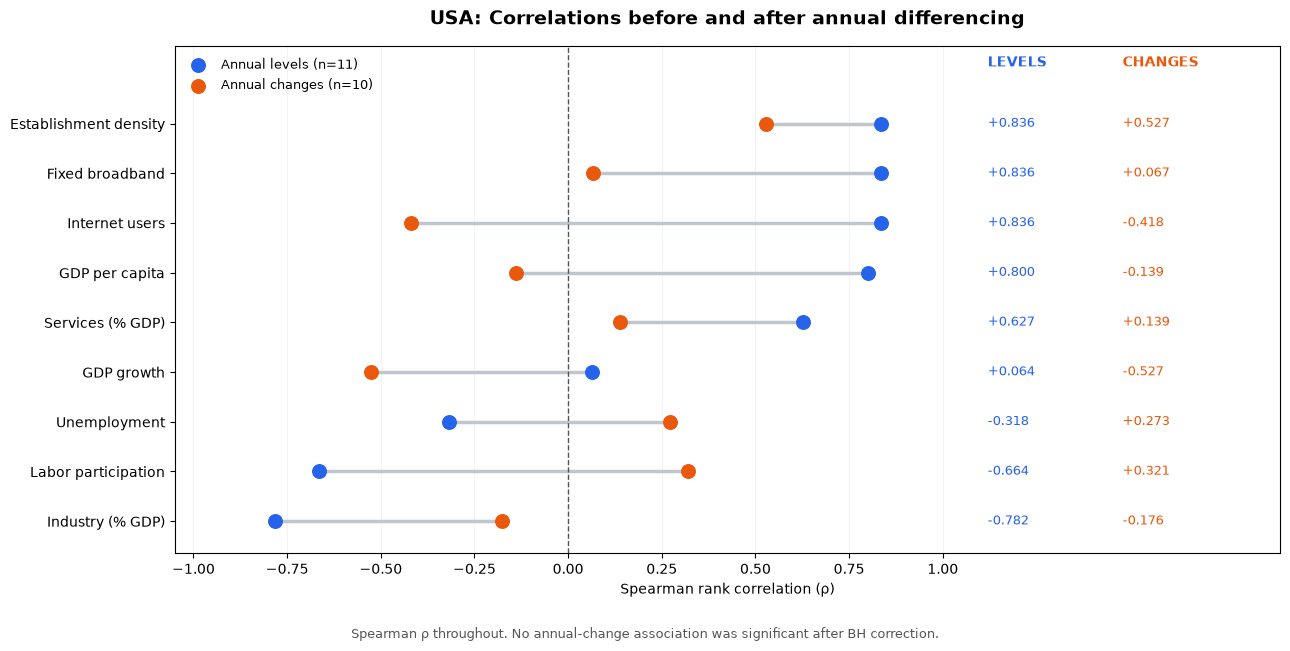

In [20]:
# Compare Spearman correlations in levels and annual changes
comparison_df = correlation_tests[
    ["Factor", "Correlation"]
].rename(columns={
    "Correlation": "Level correlation",
}).merge(
    change_tests[["Factor", "Correlation"]].rename(columns={
        "Correlation": "Change correlation",
    }),
    on="Factor",
    validate="one_to_one",
)

comparison_df = comparison_df.sort_values(
    "Level correlation"
).reset_index(drop=True)

factor_labels = {
    "gdp_per_capita": "GDP per capita",
    "gdp_growth": "GDP growth",
    "industry_gdp_pct": "Industry (% GDP)",
    "services_gdp_pct": "Services (% GDP)",
    "unemployment_rate": "Unemployment",
    "labor_force_participation": "Labor participation",
    "establishment_density": "Establishment density",
    "internet_users_pct": "Internet users",
    "fixed_broadband_per_100": "Fixed broadband",
}

y = np.arange(len(comparison_df))
fig, ax = plt.subplots(figsize=(13, 6.5))

for i, row in comparison_df.iterrows():
    ax.plot(
        [row["Level correlation"], row["Change correlation"]],
        [i, i], color="#BFC6CE", linewidth=2.5, zorder=1,
    )

ax.scatter(
    comparison_df["Level correlation"], y,
    s=95, color="#2563EB", label="Annual levels (n=11)", zorder=3,
)
ax.scatter(
    comparison_df["Change correlation"], y,
    s=95, color="#EA580C", label="Annual changes (n=10)", zorder=4,
)

for i, row in comparison_df.iterrows():
    ax.text(1.12, i, f"{row['Level correlation']:+.3f}",
            va="center", ha="left", color="#2563EB", fontsize=9)
    ax.text(1.48, i, f"{row['Change correlation']:+.3f}",
            va="center", ha="left", color="#EA580C", fontsize=9)

# Keep the two numeric column headings inside the figure
ax.text(1.12, 9.15, "LEVELS", fontweight="bold", color="#2563EB")
ax.text(1.48, 9.15, "CHANGES", fontweight="bold", color="#EA580C")

ax.axvline(0, color="#555555", linestyle="--", linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels(comparison_df["Factor"].map(factor_labels))
ax.set_xlim(-1.05, 1.90)
ax.set_ylim(-0.65, 9.55)
ax.set_xticks(np.arange(-1, 1.01, 0.25))
ax.set_xlabel("Spearman rank correlation (ρ)")
ax.set_title(
    "USA: Correlations before and after annual differencing",
    fontsize=14, fontweight="bold", pad=16,
)
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)
ax.legend(loc="upper left", frameon=False, fontsize=9)

fig.text(
    0.5, 0.01,
    "Spearman ρ throughout. No annual-change association was significant after BH correction.",
    ha="center", fontsize=9, color="#555555",
)
fig.tight_layout(rect=[0, 0.05, 1, 1])

figure_name = "01_levels_vs_annual_changes_2014_2024.png"
for output_dir in [
    PROJECT_ROOT / "figures/factors/static",
    PROJECT_ROOT / "ugotovitve/dejavnike",
]:
    output_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(
        output_dir / figure_name,
        dpi=300, bbox_inches="tight", facecolor="white",
    )

plt.show()

**Key findings — Levels vs. annual changes**

- Seven of nine indicators were significant in the conventional Spearman tests of annual levels after BH correction, while **none** was significant for annual changes.
- Internet usage changed from $\rho=0.836$ (levels) to $\rho=-0.418$ (annual changes), and fixed broadband from $0.836$ to $0.067$.
- GDP per capita changed from $\rho=0.800$ to $-0.139$; establishment density decreased from $0.836$ to $0.527$.

**Conclusion:** Strong level associations are not replicated by the annual-change analysis, consistent with possible shared trends. With only ten changes, a nonsignificant result does not establish the absence of an association.

## 4. Answers and interpretation

**Q1: Which factors are associated with incident-rate levels?**  Seven of nine factors had BH-adjusted $p<0.05$ in conventional Spearman tests of annual levels: internet usage, fixed broadband, establishment density, GDP per capita, and services share (positive); industry share and labor force participation (negative). GDP growth and unemployment were not significant.

**Q2: Are the associations sensitive to 2023?**  Excluding 2023 caused little change in the strongest level correlations. This suggests the exceptional 2023 peak is not their sole driver.


**Q3: Do the associations persist for annual changes?**

None of the nine Spearman correlations between annual changes was statistically significant after BH adjustment ($n=10$). Therefore, the associations observed in annual levels were not statistically supported by the annual-change analysis. This is consistent with possible shared long-term trends, but the small sample limits statistical power.


**Limitations:** The sample is small and contains consecutive years. Common trends and serial dependence can invalidate conventional correlation p-values, while first differencing reduces the sample and may hide genuine long-term relationships. The results describe publicly documented incidents rather than all cyberattacks.